In [110]:
import numpy as np # linear algebra
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
from plotly.offline import init_notebook_mode, iplot
init_notebook_mode(connected=True)

In [111]:
recipe = pd.read_json('/kaggle/input/recipe-ingredients-dataset/train.json')

In [112]:
recipe.head()

,id,cuisine,ingredients
0,10259,greek,"[romaine lettuce, black olives, grape tomatoes..."
1,25693,southern_us,"[plain flour, ground pepper, salt, tomatoes, g..."
2,20130,filipino,"[eggs, pepper, salt, mayonaise, cooking oil, g..."
3,22213,indian,"[water, vegetable oil, wheat, salt]"
4,13162,indian,"[black pepper, shallots, cornflour, cayenne pe..."


### How big is the dataset, columns and whether null exists?

In [113]:
print('Shape:',recipe.shape) 
print('Columns:',recipe.columns)

print('Whether Null exists:\n',recipe.isnull().sum())

Shape: (39774, 3)
Columns: Index(['id', 'cuisine', 'ingredients'], dtype='object')
Whether Null exists:
 id             0
cuisine        0
ingredients    0
dtype: int64


### How many unique cuisines are the

In [114]:
recipe['cuisine'].nunique()

20

### Which are the unique cuisines?

In [115]:
recipe['cuisine'].unique()

array(['greek', 'southern_us', 'filipino', 'indian', 'jamaican',
       'spanish', 'italian', 'mexican', 'chinese', 'british', 'thai',
       'vietnamese', 'cajun_creole', 'brazilian', 'french', 'japanese',
       'irish', 'korean', 'moroccan', 'russian'], dtype=object)

### How the individual ingredient column looks like

In [116]:
recipe['ingredients'][0]

['romaine lettuce',
 'black olives',
 'grape tomatoes',
 'garlic',
 'pepper',
 'purple onion',
 'seasoning',
 'garbanzo beans',
 'feta cheese crumbles']

In [117]:
recipe['ingredients'][6]

['olive oil',
 'salt',
 'medium shrimp',
 'pepper',
 'garlic',
 'chopped cilantro',
 'jalapeno chilies',
 'flat leaf parsley',
 'skirt steak',
 'white vinegar',
 'sea salt',
 'bay leaf',
 'chorizo sausage']

### How many entries are there for each cuisine?

In [118]:
recipe['cuisine'].value_counts()

italian         7838
mexican         6438
southern_us     4320
indian          3003
chinese         2673
french          2646
cajun_creole    1546
thai            1539
japanese        1423
greek           1175
spanish          989
korean           830
vietnamese       825
moroccan         821
british          804
filipino         755
irish            667
jamaican         526
russian          489
brazilian        467
Name: cuisine, dtype: int64

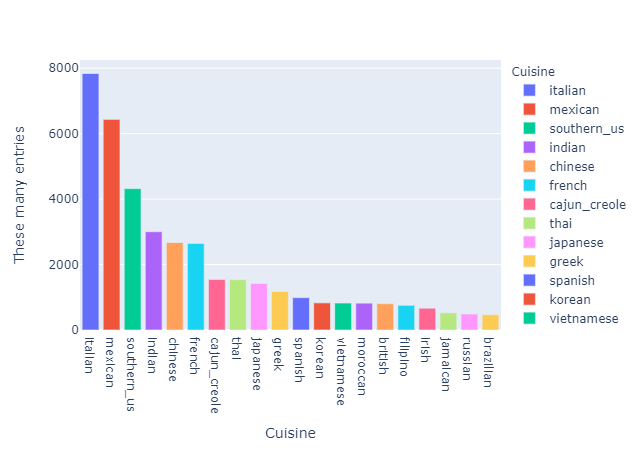

In [119]:
# bar plot for count of entries for each cuisine
x = recipe['cuisine'].value_counts().index
y = recipe['cuisine'].value_counts().values

df = pd.DataFrame({
    'Cuisine':x,
    'These many entries':y
})
#fig = sns.countplot(recipe['cuisine'])
fig = px.bar(df,
             x='Cuisine',
             y='These many entries',
             color='Cuisine')
fig.show()


### Wordcloud for all the cuisines

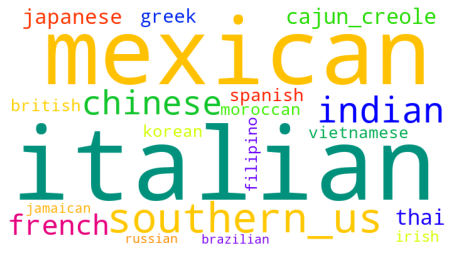

In [120]:
from wordcloud import WordCloud
x= recipe['cuisine'].values

plt.subplots(figsize = (8,8))

wordcloud = WordCloud (
                    background_color = 'white',
                    width = 712,
                    height = 384,
                    colormap = 'prism'    ).generate(' '.join(x))
plt.imshow(wordcloud) # image show
plt.axis('off') # to off the axis of x and y
plt.savefig('cuisines.png')
plt.show()

#### Italian has maximum entries followed by mexican and so on

### We need to find the ingredient which is used the max time in all the recipes

In [121]:
all_ingredients = [] # list to store all ingredients
for indiv_ingredient_list in recipe['ingredients'].values:
    for ingredient in indiv_ingredient_list:
        all_ingredients.append(ingredient)

In [122]:
len(all_ingredients) # 4 lacs ingredients 

428275

In [123]:
# Convert that list in a Pandas DataFrame so that we can apply value_counts
ingredients_together = pd.DataFrame(all_ingredients)

In [124]:
ingredients_together

,0
0,romaine lettuce
1,black olives
2,grape tomatoes
3,garlic
4,pepper
...,...
428270,garlic
428271,white sugar
428272,roma tomatoes
428273,celery


In [125]:
ingredients_together.value_counts()[0:30] # for first 30

salt                      18049
olive oil                  7972
onions                     7972
water                      7457
garlic                     7380
sugar                      6434
garlic cloves              6237
butter                     4848
ground black pepper        4785
all-purpose flour          4632
pepper                     4438
vegetable oil              4385
eggs                       3388
soy sauce                  3296
kosher salt                3113
green onions               3078
tomatoes                   3058
large eggs                 2948
carrots                    2814
unsalted butter            2782
extra-virgin olive oil     2747
ground cumin               2747
black pepper               2627
milk                       2263
chili powder               2036
oil                        1970
red bell pepper            1939
purple onion               1896
scallions                  1891
grated parmesan cheese     1886
dtype: int64

### Salt is used in max recipes

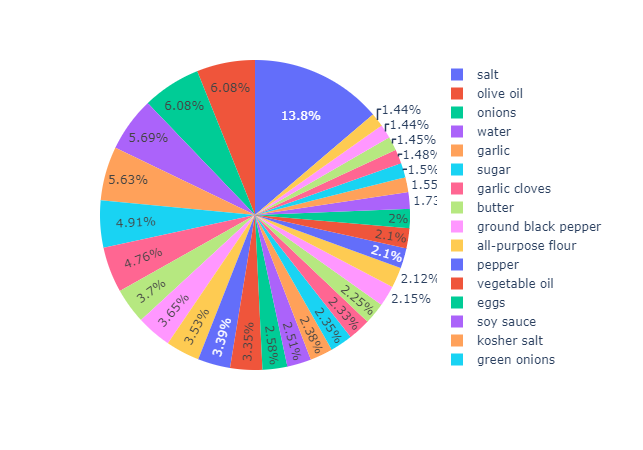

In [126]:
# bar plot for count of entries for each cuisine
x = ingredients_together.value_counts()[0:30].index.tolist()
y = ingredients_together.value_counts()[0:30].values

df = pd.DataFrame({
    'Ingredient':x,
    'These many entries':y
})
#fig = sns.countplot(recipe['cuisine'])
fig = px.pie(df,
             names='Ingredient',
             values='These many entries',
             color='Ingredient')
fig.show()


## Let's work on prediction

In [127]:
recipe['cuisine'].value_counts()

italian         7838
mexican         6438
southern_us     4320
indian          3003
chinese         2673
french          2646
cajun_creole    1546
thai            1539
japanese        1423
greek           1175
spanish          989
korean           830
vietnamese       825
moroccan         821
british          804
filipino         755
irish            667
jamaican         526
russian          489
brazilian        467
Name: cuisine, dtype: int64

### Convert column cuisine into numeric

In [128]:
recipe['cuisine'] = recipe['cuisine'].map({'italian':1,
                       'mexican':2,
                       'southern_us':3,
                       'indian':4,
                       'chinese':5,
                       'french':6,
                       'cajun_creole':7,
                       'thai':8,
                       'japanese':9,
                       'greek':10,
                       'spanish':11,
                       'korean':12,
                       'vietnamese':13,
                       'moroccan':14,
                       'british':15,
                       'filipino':16,
                       'irish':17,
                       'jamaican':18,
                       'russian':19,
                       'brazilian':20
})

### Split input and output columns

In [129]:
X = recipe.iloc[:,-1]
y = recipe['cuisine']
X

0        [romaine lettuce, black olives, grape tomatoes...
1        [plain flour, ground pepper, salt, tomatoes, g...
2        [eggs, pepper, salt, mayonaise, cooking oil, g...
3                      [water, vegetable oil, wheat, salt]
4        [black pepper, shallots, cornflour, cayenne pe...
                               ...                        
39769    [light brown sugar, granulated sugar, butter, ...
39770    [KRAFT Zesty Italian Dressing, purple onion, b...
39771    [eggs, citrus fruit, raisins, sourdough starte...
39772    [boneless chicken skinless thigh, minced garli...
39773    [green chile, jalapeno chilies, onions, ground...
Name: ingredients, Length: 39774, dtype: object

In [130]:
y

0        10
1         3
2        16
3         4
4         4
         ..
39769    17
39770     1
39771    17
39772     5
39773     2
Name: cuisine, Length: 39774, dtype: int64

In [131]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=1)

In [132]:
X_train = pd.DataFrame(X_train)
X_test = pd.DataFrame(X_test)

In [133]:
X_train

,ingredients
31255,"[yellow onion, hot water, ground turmeric, fre..."
32399,"[lime juice, zucchini, chili powder, salt, dri..."
34614,"[fresh ginger, cauliflower florets, lemon juic..."
22301,"[fish sauce, pepper, garlic, calamansi, broth,..."
4688,"[water, salt, celery, onions, chicken stock, v..."
...,...
7813,"[orange juice concentrate, garlic cloves, fres..."
32511,"[grated parmesan cheese, fresh basil leaves, e..."
5192,"[basil leaves, olive oil, extra-virgin olive o..."
12172,"[powdered sugar, large egg yolks, salt, heavy ..."


### ingredients column has everything in a list, so converting as a string

In [134]:
X_train['ingredients'] = X_train['ingredients'].apply(lambda x:  ' '.join(x))
X_test['ingredients'] = X_test['ingredients'].apply(lambda x:  ' '.join(x))

In [135]:
X_train

,ingredients
31255,yellow onion hot water ground turmeric fresh g...
32399,lime juice zucchini chili powder salt dried or...
34614,fresh ginger cauliflower florets lemon juice f...
22301,fish sauce pepper garlic calamansi broth gluti...
4688,water salt celery onions chicken stock vegetab...
...,...
7813,orange juice concentrate garlic cloves fresh c...
32511,grated parmesan cheese fresh basil leaves eggp...
5192,basil leaves olive oil extra-virgin olive oil ...
12172,powdered sugar large egg yolks salt heavy whip...


In [136]:
X_test

,ingredients
25674,water yoghurt peanut oil ground cumin ground c...
3666,lemon zest whipping cream yellow corn meal bak...
27481,salad dressing chuck roast garlic ground black...
36750,sesame seeds worcestershire sauce cucumber pep...
31926,bay leaves cayenne pepper ground cloves vegeta...
...,...
23536,shredded cheddar cheese ricotta cheese eggs Al...
30857,cajun seasoning onions water hot Italian sausa...
36586,eggplant large garlic cloves veal shanks large...
17770,ground pepper cilantro scallions seedless cucu...


In [137]:
# Applying BoW
from sklearn.feature_extraction.text import CountVectorizer

In [144]:
cv = CountVectorizer()
X_train_bow = cv.fit_transform(X_train['ingredients']).toarray()
X_test_bow = cv.transform(X_test['ingredients']).toarray()

In [145]:
X_train_bow.shape

(31819, 2887)

In [146]:
from sklearn.naive_bayes import GaussianNB
gnb = GaussianNB()

gnb.fit(X_train_bow,y_train)

y_pred = gnb.predict(X_test_bow)

from sklearn.metrics import accuracy_score,confusion_matrix
accuracy_score(y_test,y_pred)

0.24349465744814583